# DA241o Assignment 3, Notebook 1: Descriptive Analysis

**Team 9, Hidden Layers.** *Price Dispersion and the Brand Premium for Chemically Identical Medicines on Indian E-Pharmacies under DPCO Price Control.*

**Purpose.** Validate the dataset, build the variables defined in Assignment 2, and produce the descriptive evidence for SQ1 to SQ3 and for H2 to H5, before any regression.

**Input.** `HiddenLayers_dataset_DA241o.xlsx`, beside this notebook. Sheet `listings` holds one row per listing; `formulations` holds the constants from Assignment 2 Table A3; `substitutes` holds the full brand list per formulation; `README` documents every column.

**Outputs.** Every table is saved as a CSV and every figure as a PNG in `outputs/`: Figures 1 to 4 and Figure 6 (`figure6_annual_cost.png`, the annual cost of chronic medicines). `outputs/listings_clean.csv` is the input to Notebook 2.

**To run on Colab.** Choose *Runtime > Run all* and upload the workbook when prompted. The last cell downloads `outputs.zip`.

## 1. Setup

### 1.1 Required packages

This notebook needs pandas, numpy, scipy and matplotlib, plus `openpyxl` so pandas can read the `.xlsx` workbook. The cell below checks whether each package can be imported and, only if one is missing, installs it with `pip` into **the Python running this kernel** (`sys.executable`), so it works whichever interpreter or Colab runtime is selected. If nothing is missing, it installs nothing and does not go online.

It then prints the Python and package versions, as a record of the environment that produced the outputs.

In [1]:
import importlib.util, subprocess, sys

REQUIRED = {"openpyxl": "openpyxl"}  # import name -> pip name
missing = [pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
    importlib.invalidate_caches()
else:
    print("All required packages present.")

import numpy, pandas, scipy, matplotlib, openpyxl
print(f"Python {sys.version.split()[0]} | " + " | ".join(
    f"{m.__name__} {m.__version__}" for m in (numpy, pandas, scipy, matplotlib, openpyxl)))

All required packages present.
Python 3.13.7 | numpy 2.3.3 | pandas 2.3.2 | scipy 1.16.2 | matplotlib 3.10.6 | openpyxl 3.1.5


In [2]:
import sys, shutil, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats
from IPython.display import display

IN_COLAB = "google.colab" in sys.modules
DATASET = Path("HiddenLayers_dataset_DA241o.xlsx")

if IN_COLAB and not DATASET.exists():
    from google.colab import files
    files.upload()

SHEETS = pd.read_excel(DATASET, sheet_name=None)     # needs openpyxl
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)

pd.set_option("display.max_columns", 40, "display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 9})
CAPPED_COLOR, UNCAPPED_COLOR, ANCHOR_COLOR = "#1f6f8b", "#d98c2b", "#b3202a"
SOURCE = ("Source: Tata 1mg listings recorded 12 and 13 October 2026; NPPA S.O. 1575(E); "
          "PMBI product list; authors' calculations.")

def save(df, name, index=True):
    """Write a table to outputs/ and show it."""
    df.to_csv(OUT / f"{name}.csv", index=index)
    display(df)

## 2. Formulation constants (Assignment 2, Table A3)

The constants are read from the workbook's `formulations` sheet. A copy of Assignment 2 Table A3 is kept in the code below, and the sheet must match it exactly, so an accidental edit to the workbook stops the notebook.


In [3]:
# Assignment 2 Table A3, kept in code as the reference the workbook is checked against.
# Ceilings: NPPA S.O. 1575(E), 25 March 2026, Rs per tablet, excluding tax.
# Jan Aushadhi: PMBI product list, MRP per tablet. None = not stocked.
rows = [
 # id,        name,                         category,           therapy,   capped, ceiling, ja,    n_subs, listings
 ("AZI500",   "Azithromycin 500 mg",        "Antibiotic",       "Acute",   1, 24.14, 13.13, 1137, 443),
 ("MET1000SR","Metformin 1000 mg SR",       "Antidiabetic",     "Chronic", 1,  4.15,  1.36,   91,  91),
 ("MON10",    "Montelukast 10 mg",          "Respiratory",      "Chronic", 1, 16.84,  2.04,   34,  34),
 ("TEL40",    "Telmisartan 40 mg",          "Antihypertensive", "Chronic", 1,  6.92,  1.24,  463, 436),
 ("TEN20",    "Teneligliptin 20 mg",        "Antidiabetic",     "Chronic", 1, 11.35,  2.06,  200, 200),
 ("ACE100",   "Aceclofenac 100 mg",         "NSAID",            "Acute",   0, None,   0.82,   70,  65),
 ("ATE50",    "Atenolol 50 mg",             "Antihypertensive", "Chronic", 0, None,   0.49,   66,  66),
 ("DAP10",    "Dapagliflozin 10 mg",        "Antidiabetic",     "Chronic", 0, None,   3.30,  169, 170),
 ("LEV5",     "Levocetirizine 5 mg",        "Antiallergic",     "Acute",   0, None,   None,  489, 146),
 ("MET500SR", "Metformin 500 mg SR",        "Antidiabetic",     "Chronic", 0, None,   1.08,   57,  57),
 ("MET850IR", "Metformin 850 mg IR",        "Antidiabetic",     "Chronic", 0, None,   None,    8,   8),
 ("OLM20",    "Olmesartan Medoxomil 20 mg", "Antihypertensive", "Chronic", 0, None,   1.75,   65,  65),
 ("RAB20",    "Rabeprazole 20 mg",          "Gastrointestinal", "Acute",   0, None,   0.91,  570, 149),
 ("ROS10",    "Rosuvastatin 10 mg",         "Statin",           "Chronic", 0, None,   1.28,  284, 135),
 ("SIT100",   "Sitagliptin 100 mg",         "Antidiabetic",     "Chronic", 0, None,   8.25,   85,  85),
]
A3 = pd.DataFrame(rows, columns=["formulation_id", "formulation", "therapeutic_category", "therapy",
                                 "dpco_capped", "ceiling_price_unit", "ja_price_unit",
                                 "n_substitutes", "listings_recorded"])
META = SHEETS["formulations"]
pd.testing.assert_frame_equal(META, A3.astype({"ceiling_price_unit": float, "ja_price_unit": float}), check_dtype=False)
print("The formulations sheet matches Assignment 2 Table A3.")
META["chronic"] = (META["therapy"] == "Chronic").astype(int)
META["ja_available"] = META["ja_price_unit"].notna().astype(int)
LARGE = ["AZI500", "LEV5", "RAB20", "ROS10", "TEL40"]      # more than 200 platform substitutes
LARGE_CAPPED, LARGE_UNCAPPED = ["AZI500", "TEL40"], ["LEV5", "RAB20", "ROS10"]
META.drop(columns=["listings_recorded"]).head(15)

The formulations sheet matches Assignment 2 Table A3.


,formulation_id,formulation,therapeutic_category,therapy,dpco_capped,ceiling_price_unit,ja_price_unit,n_substitutes,chronic,ja_available
0,AZI500,Azithromycin 500 mg,Antibiotic,Acute,1,24.14,13.13,1137,0,1
1,MET1000SR,Metformin 1000 mg SR,Antidiabetic,Chronic,1,4.15,1.36,91,1,1
2,MON10,Montelukast 10 mg,Respiratory,Chronic,1,16.84,2.04,34,1,1
3,TEL40,Telmisartan 40 mg,Antihypertensive,Chronic,1,6.92,1.24,463,1,1
4,TEN20,Teneligliptin 20 mg,Antidiabetic,Chronic,1,11.35,2.06,200,1,1
5,ACE100,Aceclofenac 100 mg,NSAID,Acute,0,NaN,0.82,70,0,1
6,ATE50,Atenolol 50 mg,Antihypertensive,Chronic,0,NaN,0.49,66,1,1
7,DAP10,Dapagliflozin 10 mg,Antidiabetic,Chronic,0,NaN,3.30,169,1,1
8,LEV5,Levocetirizine 5 mg,Antiallergic,Acute,0,NaN,NaN,489,0,0
9,MET500SR,Metformin 500 mg SR,Antidiabetic,Chronic,0,NaN,1.08,57,1,1


## 3. Loading and validation

These assertions check that the workbook is the sample described in Assignment 2. If one fails, fix the data, not the assertion.

In [4]:
raw = SHEETS["listings"]
subs = SHEETS["substitutes"]

unparsed = raw[raw["selling_price_pack"].isna()]
print(f"Rows: {len(raw):,}; without a price: {len(unparsed)} ({unparsed['formulation_id'].unique().tolist()})")
df = raw[raw["selling_price_pack"].notna()].copy()

assert len(raw) == 2158
assert len(unparsed) == 8 and set(unparsed["formulation_id"]) == {"TEL40"}
assert len(df) == 2150
assert (df["role"] == "anchor").sum() == 15 and (df["role"] == "substitute").sum() == 2135
assert df["marketer"].nunique() == 1229
assert set(df["formulation_id"]) == set(META["formulation_id"])

# Per-formulation listing counts and platform totals against Table A3.
check = META.set_index("formulation_id")
assert df.groupby("formulation_id").size().sort_index().equals(check["listings_recorded"].sort_index().rename(None))
assert subs.groupby("formulation_id").size().sort_index().equals(check["n_substitutes"].sort_index().rename(None))

# The DPCO split, ceilings and therapy groups as submitted.
assert META["dpco_capped"].sum() == 5 and set(META.loc[META.dpco_capped == 1, "formulation_id"]) == {
    "AZI500", "MET1000SR", "MON10", "TEL40", "TEN20"}
assert META["chronic"].sum() == 11 and META["ja_available"].sum() == 13
assert df.groupby("formulation_id")["composition"].nunique().max() == 1
print("All sample assertions passed.")

Rows: 2,158; without a price: 8 (['TEL40'])
All sample assertions passed.


## 4. Variables (Assignment 2, Table A2)

Unit prices `sp_unit` and `mrp_unit` are computed from pack prices (price per pack ÷ `pack_units`). Percentiles use linear interpolation.

In [5]:
df = df.merge(META.drop(columns=["listings_recorded"]), on="formulation_id", how="left", validate="m:1")

df["sp_unit"] = df["selling_price_pack"] / df["pack_units"]
df["mrp_unit"] = df["mrp_pack"] / df["pack_units"]
df["discount_pct"] = (1 - df["sp_unit"] / df["mrp_unit"]) * 100
df["is_anchor"] = (df["role"] == "anchor").astype(int)
df["cheaper_alt_shown"] = df["cheaper_alt_shown"].astype(bool).astype(int)
df["bought_recently_shown"] = df["bought_recently"].notna().astype(int)
df["log_pack_units"] = np.log(df["pack_units"])
df["large_formulation"] = df["formulation_id"].isin(LARGE).astype(int)

grp = df.groupby("formulation_id")
df["p10_sp"] = grp["sp_unit"].transform(lambda s: s.quantile(.10))
df["p10_mrp"] = grp["mrp_unit"].transform(lambda s: s.quantile(.10))
df["median_sp"] = grp["sp_unit"].transform("median")
df["premium_over_p10"] = df["sp_unit"] / df["p10_sp"]
df["premium_over_min"] = df["sp_unit"] / grp["sp_unit"].transform("min")
df["premium_over_ja"] = df["sp_unit"] / df["ja_price_unit"]
df["premium_mrp_p10"] = df["mrp_unit"] / df["p10_mrp"]

threshold = df["ceiling_price_unit"] * 1.05          # ceiling plus 5% GST
df["ceiling_plus_gst"] = threshold
df["above_ceiling"] = np.where(df["dpco_capped"] == 1, (df["sp_unit"] > threshold).astype(float), np.nan)
df["above_ceiling_mrp"] = np.where(df["dpco_capped"] == 1, (df["mrp_unit"] > threshold).astype(float), np.nan)

ANCHOR = df[df["is_anchor"] == 1].set_index("formulation_id")
ORDER = META.sort_values(["dpco_capped", "formulation_id"], ascending=[False, True])["formulation_id"].tolist()

# Reproduce the anchor premiums printed in Assignment 2 Table A1.
a1 = {"MET500SR": 1.33, "MET1000SR": 1.34, "TEN20": .96, "MON10": 2.10, "TEL40": 1.49,
      "AZI500": 1.42, "MET850IR": 2.18, "ROS10": 1.06, "OLM20": 2.60, "SIT100": 4.14}
gaps = {k: abs(ANCHOR.loc[k, "premium_over_p10"] - v) for k, v in a1.items()}
assert max(gaps.values()) < .011, gaps
print("Anchor premiums reproduce Assignment 2 Table A1 to two decimals.")

Anchor premiums reproduce Assignment 2 Table A1 to two decimals.


## 5. Data checks

The checks promised in Assignment 2, plus basic consistency checks.

In [6]:
far = df[df["sp_unit"] > 10 * df["median_sp"]]
print("Listings above 10 times their formulation median:", len(far))
print("Listings with selling price above MRP:", int((df["sp_unit"] > df["mrp_unit"] + 1e-9).sum()))
print("Pack sizes:", df["pack_units"].value_counts().head(8).to_dict())

# Facts stated in Assignment 2.
flag = df[df["cheaper_alt_shown"] == 1]
print(f"\nFlagged listings: {len(flag)}; at or below formulation median: "
      f"{(flag['sp_unit'] <= flag['median_sp']).sum()}; strictly below: {(flag['sp_unit'] < flag['median_sp']).sum()}")
print(f"'Bought recently' shown on {df['bought_recently_shown'].mean():.1%} of listings")
top = df.loc[df.groupby("formulation_id")["bought_recently"].idxmax().dropna()]
print(f"The highest 'bought recently' count picks the anchor in {int(top['is_anchor'].sum())} of 15 formulations")

Listings above 10 times their formulation median: 0
Listings with selling price above MRP: 0
Pack sizes: {10.0: 1375, 3.0: 336, 15.0: 279, 14.0: 66, 5.0: 55, 6.0: 16, 30.0: 10, 7.0: 7}

Flagged listings: 87; at or below formulation median: 77; strictly below: 76
'Bought recently' shown on 19.9% of listings
The highest 'bought recently' count picks the anchor in 9 of 15 formulations


In [7]:
# Rows repeating the same brand, marketer and pack size within a formulation.
key = ["formulation_id", "brand", "marketer", "pack_units"]
df["repeat_group"] = df.duplicated(key, keep=False).astype(int)
df["repeat_extra"] = df.duplicated(key, keep="first").astype(int)   # dropped in Notebook 2 robustness
rep = df[df["repeat_group"] == 1].sort_values(key)
same_price = rep.groupby(key)["sp_unit"].nunique().eq(1)
print(f"Rows in repeated groups: {len(rep)}; groups: {same_price.size}; extra rows: {df['repeat_extra'].sum()}; "
      f"groups with one identical price: {same_price.sum()}")
save(rep[["formulation_id", "brand", "marketer", "pack_units", "sp_unit", "mrp_unit"]], "check_repeated_rows", index=False)

Rows in repeated groups: 27; groups: 13; extra rows: 14; groups with one identical price: 3


,formulation_id,brand,marketer,pack_units,sp_unit,mrp_unit
971,AZI500,Azidin 500mg Tablet,Axodin Pharmaceuticals Pvt. Ltd.,3.0,21.633333,22.343333
972,AZI500,Azidin 500mg Tablet,Axodin Pharmaceuticals Pvt. Ltd.,3.0,21.166667,21.876667
1014,AZI500,Azigum 500mg Tablet,Pharmasynth Formulations Ltd,3.0,20.400000,21.063333
1015,AZI500,Azigum 500mg Tablet,Pharmasynth Formulations Ltd,3.0,19.733333,21.250000
1030,AZI500,Azikem 500mg Tablet,Synokem Pharmaceuticals Ltd,3.0,17.133333,25.173333
1031,AZI500,Azikem 500mg Tablet,Synokem Pharmaceuticals Ltd,3.0,24.400000,25.173333
1055,AZI500,Azilife 500mg Tablet,Symbiosis Pharmaceuticals Pvt Ltd,3.0,23.600000,24.376667
1056,AZI500,Azilife 500mg Tablet,Symbiosis Pharmaceuticals Pvt Ltd,3.0,20.866667,21.563333
1057,AZI500,Azilife 500mg Tablet,Symbiosis Pharmaceuticals Pvt Ltd,3.0,21.033333,22.626667
1062,AZI500,Azim 500mg Tablet,Hamax Pharmaceuticals,3.0,22.666667,23.400000


### Audit of the "cheaper alternative" flag

The stored flag `cheaper_alt_shown` marks only 87 listings. It misses the usual wording of the prompt, **"Save X% more with alternative"**, because of the percentage, so it catches only listings whose prompt shows no percentage, plus a few with a generic-alternative line.

The `listings` sheet also holds the corrected variables. `cheaper_alt_shown` is kept unchanged, as submitted.

- `alt_widget_shown`: 1 if the listing shows the alternative prompt, with or without a percentage.
- `alt_saving_pct`: the percentage shown, if any.

Prices and "bought recently" counts matched the saved pages when the dataset was built (`build_dataset.py` checked every listing), so the error is limited to this flag.


In [8]:
# Corrected prompt indicator from the listings sheet (see the README sheet).
df["alt_widget_shown"] = df["alt_widget_shown"].astype(int)

assert df["alt_widget_shown"].sum() == 1932 and df["alt_saving_pct"].notna().sum() == 1851
assert (df.loc[df["cheaper_alt_shown"] == 1, "alt_widget_shown"] == 1).all()

df["price_to_median"] = df["sp_unit"] / df["median_sp"]
group = np.select([df["alt_widget_shown"] == 0, df["alt_saving_pct"].isna()],
                  ["No alternative prompt", "Prompt, no percentage"], "Prompt with percentage")
a1 = df.groupby(group).agg(listings=("sp_unit", "size"), stored_flag_set=("cheaper_alt_shown", "sum"), anchors=("is_anchor", "sum"),
                           median_price_to_formulation_median=("price_to_median", "median"),
                           median_premium_over_p10=("premium_over_p10", "median"))
a1["share_of_listings_pct"] = 100 * a1["listings"] / len(df)
save(a1.round(3), "table_alt_flag_audit")

bands = pd.cut(df["alt_saving_pct"], [0, 10, 20, 30, 40, 50, 60, 100], right=False)
a2 = df.groupby(bands, observed=True).agg(listings=("sp_unit", "size"), median_price_to_formulation_median=("price_to_median", "median"))
save(a2.round(3), "table_alt_saving_bands")

a3 = df[df["is_anchor"] == 1].set_index("formulation_id").loc[ORDER, ["brand", "alt_widget_shown", "alt_saving_pct", "cheaper_alt_shown"]]
save(a3, "table_alt_anchors")

w = df.groupby("alt_widget_shown")["sp_unit"].size().to_dict()
at = df[df["alt_widget_shown"] == 1]
print(f"Corrected: {w[1]:,} of {len(df):,} listings show the prompt ({100 * w[1] / len(df):.1f}%). Stored flag: {df['cheaper_alt_shown'].sum()}.")
print(f"Listings with the prompt at or below their formulation median: {(at['sp_unit'] <= at['median_sp']).sum():,} of {len(at):,}")

,listings,stored_flag_set,anchors,median_price_to_formulation_median,median_premium_over_p10,share_of_listings_pct
No alternative prompt,218,0,4,0.791,0.955,10.140
Prompt with percentage,1851,6,10,1.022,1.286,86.093
"Prompt, no percentage",81,81,1,0.862,1.003,3.767


,listings,median_price_to_formulation_median
alt_saving_pct,,
"[0, 10)",89,0.899
"[10, 20)",463,0.969
"[20, 30)",542,1.029
"[30, 40)",446,1.058
"[40, 50)",222,1.186
"[50, 60)",52,1.595
"[60, 100)",37,2.145


,brand,alt_widget_shown,alt_saving_pct,cheaper_alt_shown
formulation_id,,,,
AZI500,Azithral 500 Tablet,1,33.0,0
MET1000SR,Glycomet 1gm Tablet SR,1,16.0,0
MON10,Montair 10 Tablet,1,51.0,0
TEL40,Telma 40 Tablet,1,42.0,0
TEN20,Tenepla Tablet,0,NaN,0
ACE100,Hifenac Tablet,1,55.0,0
ATE50,Aten 50 Tablet,1,45.0,0
DAP10,Forxiga 10mg Tablet,1,70.0,0
LEV5,Levocet Tablet,1,57.0,0


Corrected: 1,932 of 2,150 listings show the prompt (89.9%). Stored flag: 87.
Listings with the prompt at or below their formulation median: 905 of 1,932


## 6. Coverage of the five large formulations

Five formulations have more than 200 platform substitutes and were not recorded in full. This section describes which part of each brand list the sample holds, using each listing's position (`rank`) in the `substitutes` sheet. Brands are matched by name, so unmatched rows are reported.

A sample that stops part-way down the list would have its rank concentrated at the top. A random draw would have a median rank near the middle of the list.

In [9]:
s = subs.copy()
s["key"] = s["brand"].str.strip().str.lower()
first_rank = s.groupby(["formulation_id", "key"])["rank"].min().rename("list_rank").reset_index()
df["key"] = df["brand"].str.strip().str.lower()
df = df.merge(first_rank, on=["formulation_id", "key"], how="left", validate="m:1")

out = []
for f in META.sort_values("n_substitutes", ascending=False)["formulation_id"]:
    x, L = df[df["formulation_id"] == f], (subs["formulation_id"] == f).sum()
    m = x["list_rank"].dropna()
    out.append({"formulation_id": f, "capped": x["dpco_capped"].iloc[0], "platform_substitutes": L,
                "listings": len(x), "coverage_pct": 100 * len(x) / L, "matched_to_list": len(m),
                "median_rank_as_pct_of_list": 100 * m.median() / L,
                "in_first_50_ranks": int((m < 50).sum()), "in_last_half_of_list": int((m >= L / 2).sum())})
coverage = pd.DataFrame(out).set_index("formulation_id").round(1)
save(coverage, "table_coverage")

,capped,platform_substitutes,listings,coverage_pct,matched_to_list,median_rank_as_pct_of_list,in_first_50_ranks,in_last_half_of_list
formulation_id,,,,,,,,
AZI500,1,1137,443,39.0,366,42.9,50,167
RAB20,0,570,149,26.1,142,23.9,50,43
LEV5,0,489,146,29.9,142,32.4,50,55
TEL40,1,463,436,94.2,369,44.9,50,163
ROS10,0,284,135,47.5,123,29.6,50,44
TEN20,1,200,200,100.0,172,45.2,50,77
DAP10,0,169,170,100.6,165,47.3,52,78
MET1000SR,1,91,91,100.0,83,44.0,47,39
SIT100,0,85,85,100.0,83,48.2,50,40


### Does partial coverage change the dispersion?

The `substitutes` sheet holds a listed unit price for nearly every brand, including brands with no row in `listings`. So dispersion can be computed on the full brand list and set beside dispersion on the recorded listings.

In [10]:
def dispersion(x):
    x = pd.Series(x).dropna()
    return pd.Series({"cv": x.std(ddof=1) / x.mean(), "p75_p25": x.quantile(.75) / x.quantile(.25),
                      "max_min": x.max() / x.min(), "n": len(x)})

rec = df.groupby("formulation_id")["sp_unit"].apply(dispersion).unstack()
full = subs.groupby("formulation_id")["price_per_unit_listed"].apply(dispersion).unstack()
print("Share of list rows with a listed unit price:", round(subs["price_per_unit_listed"].notna().mean(), 3))
print("Units in the list:", subs["unit"].value_counts().head(6).to_dict())
cmp_ = rec.merge(full, left_index=True, right_index=True, suffixes=("_recorded", "_full_list")).loc[META.sort_values("n_substitutes", ascending=False)["formulation_id"]]
cmp_["n_recorded"], cmp_["n_full_list"] = cmp_.pop("n_recorded").astype(int), cmp_.pop("n_full_list").astype(int)
save(cmp_.round(3), "table_coverage_dispersion")

Share of list rows with a listed unit price: 1.0
Units in the list: {'tablet': 3640, 'tablet sr': 148}


,cv_recorded,p75_p25_recorded,max_min_recorded,cv_full_list,p75_p25_full_list,max_min_full_list,n_recorded,n_full_list
formulation_id,,,,,,,,
AZI500,0.096,1.112,1.736,0.088,1.097,1.736,443,1137
RAB20,0.496,1.769,21.467,0.480,1.411,36.000,149,570
LEV5,0.545,1.663,36.333,0.455,1.335,36.325,146,489
TEL40,0.155,1.185,6.055,0.149,1.185,6.058,436,463
ROS10,0.361,1.635,18.178,0.339,1.565,18.180,135,284
TEN20,0.183,1.218,5.383,0.180,1.206,5.382,200,200
DAP10,0.360,1.327,9.732,0.347,1.325,9.732,170,169
MET1000SR,0.117,1.157,2.179,0.118,1.157,2.180,91,91
SIT100,0.341,1.270,11.919,0.344,1.270,11.904,85,85


## 7. Table 1: Formulations

Prices are per tablet in rupees, at selling price.

In [11]:
q = df.groupby("formulation_id")["sp_unit"].agg(
    min="min", p10=lambda s: s.quantile(.10), median="median", max="max")
t1 = META.set_index("formulation_id")[["formulation", "therapeutic_category", "therapy", "dpco_capped",
                                        "ceiling_price_unit", "ja_price_unit", "n_substitutes"]].join(
    df.groupby("formulation_id").size().rename("listings")).join(q).loc[ORDER]
t1["dpco"] = t1.pop("dpco_capped").map({1: "Capped", 0: "Uncapped"})
save(t1.round(2), "table1_formulations")
print(SOURCE)

,formulation,therapeutic_category,therapy,ceiling_price_unit,ja_price_unit,n_substitutes,listings,min,p10,median,max,dpco
formulation_id,,,,,,,,,,,,
AZI500,Azithromycin 500 mg,Antibiotic,Acute,24.14,13.13,1137,443,14.60,17.81,20.30,25.35,Capped
MET1000SR,Metformin 1000 mg SR,Antidiabetic,Chronic,4.15,1.36,91,91,2.00,3.15,3.48,4.36,Capped
MON10,Montelukast 10 mg,Respiratory,Chronic,16.84,2.04,34,34,1.25,8.43,11.45,17.67,Capped
TEL40,Telmisartan 40 mg,Antihypertensive,Chronic,6.92,1.24,463,436,1.20,4.65,5.90,7.27,Capped
TEN20,Teneligliptin 20 mg,Antidiabetic,Chronic,11.35,2.06,200,200,2.20,7.11,9.26,11.84,Capped
ACE100,Aceclofenac 100 mg,NSAID,Acute,NaN,0.82,70,65,1.82,2.19,2.86,16.30,Uncapped
ATE50,Atenolol 50 mg,Antihypertensive,Chronic,NaN,0.49,66,66,0.80,1.19,1.74,7.36,Uncapped
DAP10,Dapagliflozin 10 mg,Antidiabetic,Chronic,NaN,3.30,169,170,4.85,9.88,13.60,47.20,Uncapped
LEV5,Levocetirizine 5 mg,Antiallergic,Acute,NaN,NaN,489,146,0.40,2.28,3.42,14.53,Uncapped


Source: Tata 1mg listings recorded 12 and 13 October 2026; NPPA S.O. 1575(E); PMBI product list; authors' calculations.


## 8. Table 2: Anchor premiums (SQ1, H1, H5)

The anchor is the leading brand. The percentile rank is the anchor's position in its formulation's price distribution, which is the main evidence for H5 because there are only 15 anchors.

In [12]:
rows = []
for f in ORDER:
    x, a = df[df["formulation_id"] == f], ANCHOR.loc[f]
    rows.append({"formulation_id": f, "dpco": "Capped" if a.dpco_capped else "Uncapped",
                 "anchor_brand": a.brand, "anchor_sp_unit": a.sp_unit,
                 "premium_over_p10": a.premium_over_p10, "premium_over_min": a.premium_over_min,
                 "premium_over_ja": a.premium_over_ja,
                 "percentile_rank": stats.percentileofscore(x["sp_unit"], a.sp_unit, kind="rank")})
t2 = pd.DataFrame(rows).set_index("formulation_id")
save(t2.round(2), "table2_anchor_premiums")
t2g = t2.groupby("dpco")[["anchor_sp_unit", "premium_over_p10", "premium_over_min", "premium_over_ja", "percentile_rank"]].median()
save(t2g.round(2), "table2b_group_medians")

# Listing-level medians, which use all listings and not only anchors.
t2c = df.groupby("dpco_capped")[["premium_over_p10", "premium_over_min", "premium_over_ja"]].median().rename(index={1: "Capped", 0: "Uncapped"})
save(t2c.round(2), "table2c_listing_medians")
c_, u_ = t2.loc[t2["dpco"] == "Capped", "premium_over_p10"], t2.loc[t2["dpco"] == "Uncapped", "premium_over_p10"]
U_, p_ = stats.mannwhitneyu(c_, u_, alternative="two-sided", method="exact")
print(f"Anchor premium, capped vs uncapped: exact rank-sum p = {p_:.3f}, rank-biserial = {2 * U_ / (len(c_) * len(u_)) - 1:.2f}")
print("Anchors above the 78th percentile:", int((t2["percentile_rank"] > 78).sum()), "of 15")
print("Lowest ranks:", t2["percentile_rank"].nsmallest(3).round(1).to_dict())

,dpco,anchor_brand,anchor_sp_unit,premium_over_p10,premium_over_min,premium_over_ja,percentile_rank
formulation_id,,,,,,,
AZI500,Capped,Azithral 500 Tablet,25.35,1.42,1.74,1.93,100.00
MET1000SR,Capped,Glycomet 1gm Tablet SR,4.23,1.34,2.11,3.11,95.60
MON10,Capped,Montair 10 Tablet,17.67,2.09,14.13,8.66,100.00
TEL40,Capped,Telma 40 Tablet,6.93,1.49,5.78,5.59,92.55
TEN20,Capped,Tenepla Tablet,6.85,0.96,3.11,3.33,9.50
ACE100,Uncapped,Hifenac Tablet,6.22,2.84,3.42,7.59,84.62
ATE50,Uncapped,Aten 50 Tablet,2.68,2.25,3.35,5.47,89.39
DAP10,Uncapped,Forxiga 10mg Tablet,40.43,4.09,8.34,12.25,99.41
LEV5,Uncapped,Levocet Tablet,5.28,2.32,13.20,NaN,80.14


,anchor_sp_unit,premium_over_p10,premium_over_min,premium_over_ja,percentile_rank
dpco,,,,,
Capped,6.93,1.42,3.11,3.33,95.60
Uncapped,7.60,2.46,5.61,7.30,88.54


,premium_over_p10,premium_over_min,premium_over_ja
dpco_capped,,,
Uncapped,1.39,4.10,4.55
Capped,1.20,3.62,3.69


Anchor premium, capped vs uncapped: exact rank-sum p = 0.040, rank-biserial = -0.68
Anchors above the 78th percentile: 13 of 15
Lowest ranks: {'TEN20': 9.5, 'ROS10': 16.7, 'LEV5': 80.1}


### The two low anchors

Thirteen anchors sit near the top of their formulations. Tenepla (TEN20) and Rosuvas (ROS10) do not, so each is examined here.

**Rosuvas.** Its saved page says the manufacturer has discontinued this pack, and no other listing in the sample was marked discontinued or sold out when the data were recorded. The stored ₹8.98 is the price of the discontinued 10-tablet pack. The current 15-tablet pack (`current_*_pack` columns) costs ₹360 (MRP ₹375), or ₹24.00 per tablet. Table 2 keeps the value as submitted; the columns below show the anchor at the current pack.

**Tenepla.** Its price is real, but it carries the largest discount in its formulation, so its position differs sharply between selling price and MRP. It is also not the formulation's best seller.

In [13]:
ros_i = df.index[(df["formulation_id"] == "ROS10") & (df["is_anchor"] == 1)][0]
ros_pack, ros_sp, ros_mrp = int(df.loc[ros_i, "current_pack_units"]), df.loc[ros_i, "current_sp_pack"], df.loc[ros_i, "current_mrp_pack"]
assert (ros_pack, ros_sp, ros_mrp) == (15, 360, 375)

fix = df[["formulation_id", "sp_unit", "mrp_unit"]].copy()
fix.loc[ros_i, "sp_unit"], fix.loc[ros_i, "mrp_unit"] = ros_sp / ros_pack, ros_mrp / ros_pack
df["premium_over_p10_fix"] = fix["sp_unit"] / fix.groupby("formulation_id")["sp_unit"].transform(lambda v: v.quantile(.10))
df["ros_anchor_row"] = (df.index == ros_i).astype(int)

rows = []
for label, f, price, mrp in [("Tenepla, as recorded", "TEN20", None, None), ("Rosuvas, as recorded", "ROS10", None, None),
                             ("Rosuvas, current 15-tablet pack", "ROS10", ros_sp / ros_pack, ros_mrp / ros_pack)]:
    x = fix[fix["formulation_id"] == f]
    a = ANCHOR.loc[f]
    sp_, mrp_ = (price, mrp) if price else (a.sp_unit, a.mrp_unit)
    others_sp, others_mrp = (x.drop(index=ros_i), ) * 2 if price else (x, x)
    vals_sp = pd.concat([others_sp["sp_unit"], pd.Series([sp_])]) if price else x["sp_unit"]
    vals_mrp = pd.concat([others_mrp["mrp_unit"], pd.Series([mrp_])]) if price else x["mrp_unit"]
    y = df[df["formulation_id"] == f]
    rows.append({"anchor": label, "sp_unit": sp_, "mrp_unit": mrp_, "discount_pct": 100 * (1 - sp_ / mrp_),
                 "premium_over_p10": sp_ / vals_sp.quantile(.10), "premium_mrp_p10": mrp_ / vals_mrp.quantile(.10),
                 "percentile_at_sp": stats.percentileofscore(vals_sp, sp_, kind="rank"),
                 "percentile_at_mrp": stats.percentileofscore(vals_mrp, mrp_, kind="rank"),
                 "largest_discount_in_formulation": y["discount_pct"].max(),
                 "bought_recently": a.bought_recently, "bought_rank": int((y["bought_recently"] > a.bought_recently).sum()) + 1 if pd.notna(a.bought_recently) else np.nan,
                 "brands_with_count": int(y["bought_recently"].notna().sum())})
save(pd.DataFrame(rows).set_index("anchor").round(2).T, "table_anchor_exceptions")

# Table 2 summaries again, with Rosuvas at its current pack.
t2fix = t2.copy()
fx = fix[fix["formulation_id"] == "ROS10"]["sp_unit"]
t2fix.loc["ROS10", "anchor_sp_unit"] = ros_sp / ros_pack
t2fix.loc["ROS10", "premium_over_p10"] = (ros_sp / ros_pack) / fx.quantile(.10)
t2fix.loc["ROS10", "percentile_rank"] = stats.percentileofscore(fx, ros_sp / ros_pack, kind="rank")
c_, u_ = t2fix.loc[t2fix["dpco"] == "Capped", "premium_over_p10"], t2fix.loc[t2fix["dpco"] == "Uncapped", "premium_over_p10"]
U_, p_ = stats.mannwhitneyu(c_, u_, alternative="two-sided", method="exact")
summ = pd.Series({"median_anchor_premium_capped": c_.median(), "median_anchor_premium_uncapped": u_.median(), "exact_p": p_,
                  "rank_biserial": 2 * U_ / (len(c_) * len(u_)) - 1, "anchors_above_78th_percentile": int((t2fix["percentile_rank"] > 78).sum()),
                  "rosuvas_premium": t2fix.loc["ROS10", "premium_over_p10"], "rosuvas_percentile": t2fix.loc["ROS10", "percentile_rank"]})
save(summ.round(3).to_frame("rosuvas_at_current_pack"), "table2d_rosuvas_sensitivity")

anchor,"Tenepla, as recorded","Rosuvas, as recorded","Rosuvas, current 15-tablet pack"
sp_unit,6.85,8.98,24.00
mrp_unit,10.76,9.28,25.00
discount_pct,36.36,3.25,4.00
premium_over_p10,0.96,1.06,2.84
premium_mrp_p10,1.45,1.04,2.81
percentile_at_sp,9.50,16.30,97.78
percentile_at_mrp,73.00,16.30,97.41
largest_discount_in_formulation,36.36,34.84,34.84
bought_recently,211.00,NaN,NaN
bought_rank,7.00,NaN,NaN


,rosuvas_at_current_pack
median_anchor_premium_capped,1.423
median_anchor_premium_uncapped,2.719
exact_p,0.008
rank_biserial,-0.840
anchors_above_78th_percentile,14.000
rosuvas_premium,2.838
rosuvas_percentile,97.778


### Table 2e: The leading brand by "bought recently"

The anchor is a brand chosen in advance. This table replaces it with a leader taken from the data: the listing with the highest "bought recently" count in each formulation. The count is shown on only 19.9% of listings, it is a platform display and not a sales figure, and its time window is not stated, so it ranks brands roughly.

The purchase-weighted premium uses the counts as weights across listings that show one. It is the closest available measure of the premium buyers actually pay, though it leaves out listings with no count.

In [14]:
def weighted_median(v, w):
    o = np.argsort(v)
    v, w = np.asarray(v)[o], np.asarray(w, float)[o]
    return v[np.searchsorted(np.cumsum(w), .5 * w.sum())]

lead_idx = df.groupby("formulation_id")["bought_recently"].idxmax()
df["is_leader"] = df.index.isin(lead_idx).astype(int)

rows = []
for f in ORDER:
    x = df[df["formulation_id"] == f]
    l, a = df.loc[lead_idx[f]], ANCHOR.loc[f]
    seen = x[x["bought_recently"].notna()]
    rows.append({"formulation_id": f, "dpco": "Capped" if l.dpco_capped else "Uncapped", "leader": l.brand, "marketer": l.marketer,
                 "same_as_anchor": bool(l.is_anchor), "bought_recently": int(l.bought_recently), "brands_with_count": len(seen),
                 "leader_sp_unit": l.sp_unit, "leader_premium": l.premium_over_p10, "anchor_premium": a.premium_over_p10,
                 "leader_percentile": stats.percentileofscore(x["sp_unit"], l.sp_unit, kind="rank"),
                 "leader_premium_over_ja": l.premium_over_ja,
                 "weighted_median_premium": weighted_median(seen["premium_over_p10"], seen["bought_recently"]),
                 "unweighted_median_premium": x["premium_over_p10"].median()})
t2e = pd.DataFrame(rows).set_index("formulation_id")
save(t2e.round(2), "table2e_leader_by_bought_recently")

rows = []
for m_ in ["leader_premium", "anchor_premium", "weighted_median_premium", "unweighted_median_premium", "leader_percentile"]:
    c_, u_ = t2e.loc[t2e["dpco"] == "Capped", m_], t2e.loc[t2e["dpco"] == "Uncapped", m_]
    U_, p_ = stats.mannwhitneyu(c_, u_, alternative="two-sided", method="exact")
    rows.append({"measure": m_, "median_capped": c_.median(), "median_uncapped": u_.median(), "exact_p": p_, "rank_biserial": 2 * U_ / (len(c_) * len(u_)) - 1})
save(pd.DataFrame(rows).round(3), "table2f_leader_tests", index=False)
print("Leaders that are the anchor:", int(t2e["same_as_anchor"].sum()), "of 15")
print("Leaders above the 78th percentile:", int((t2e["leader_percentile"] > 78).sum()), "| below the median:", int((t2e["leader_percentile"] < 50).sum()))
print("Leaders with premium above 1:", int((t2e["leader_premium"] > 1).sum()))

,dpco,leader,marketer,same_as_anchor,bought_recently,brands_with_count,leader_sp_unit,leader_premium,anchor_premium,leader_percentile,leader_premium_over_ja,weighted_median_premium,unweighted_median_premium
formulation_id,,,,,,,,,,,,,
AZI500,Capped,Azithral 500 Tablet,Alembic Pharmaceuticals Ltd,True,4605,27,25.35,1.42,1.42,100.00,1.93,1.38,1.14
MET1000SR,Capped,Glycomet 1gm Tablet SR,USV Private Limited,True,3318,17,4.23,1.34,1.34,95.60,3.11,1.34,1.10
MON10,Capped,Montair 10 Tablet,Cipla Ltd,True,615,12,17.67,2.09,2.09,100.00,8.66,2.09,1.36
TEL40,Capped,Telma 40 Tablet,Glenmark Pharmaceuticals Ltd,True,5203,61,6.93,1.49,1.49,92.55,5.59,1.49,1.27
TEN20,Capped,Dynaglipt Tablet,Mankind Pharma Ltd,False,1199,32,8.53,1.20,0.96,24.00,4.14,1.22,1.30
ACE100,Uncapped,Zerodol Tablet,Ipca Laboratories Ltd,False,366,5,7.38,3.37,2.84,93.85,9.00,3.37,1.31
ATE50,Uncapped,Aten 50 Tablet,Zydus Cadila,True,560,6,2.68,2.25,2.25,89.39,5.47,2.25,1.46
DAP10,Uncapped,Oxra 10mg Tablet,Sun Pharmaceutical Industries Ltd,False,3439,60,17.50,1.77,4.09,87.06,5.30,1.71,1.38
LEV5,Uncapped,Levocetrizen 5mg Tablet,Leeford Healthcare Ltd,False,2660,32,2.28,1.00,2.32,10.96,NaN,1.77,1.50


,measure,median_capped,median_uncapped,exact_p,rank_biserial
0,leader_premium,1.423,1.977,0.129,-0.52
1,anchor_premium,1.423,2.461,0.040,-0.68
2,weighted_median_premium,1.382,1.978,0.040,-0.68
3,unweighted_median_premium,1.269,1.400,0.013,-0.80
4,leader_percentile,95.604,88.543,0.254,0.40


Leaders that are the anchor: 9 of 15
Leaders above the 78th percentile: 12 | below the median: 2
Leaders with premium above 1: 15


## 9. Table 3: Dispersion (SQ1, H2)

**P75/P25 and CV are the main measures.** Max/min is reported but not relied on. The test is a Wilcoxon rank-sum test (5 capped vs 10 uncapped) with an exact p-value. The rank-biserial effect size runs from -1 to 1; negative means capped formulations have lower dispersion.

The comparison is repeated five ways: after 1% trimming within each formulation; without all five large formulations; without only the two large capped ones; without only the three large uncapped ones; and on the full brand list.

In [15]:
capped_ids = set(META.loc[META["dpco_capped"] == 1, "formulation_id"])

def trim(x, col="sp_unit"):
    """Keep listings between each formulation's 1st and 99th percentiles."""
    g = x.groupby("formulation_id")[col]
    return x[(x[col] >= g.transform(lambda s: s.quantile(.01))) & (x[col] <= g.transform(lambda s: s.quantile(.99)))]

def ranksum(table, label):
    """Exact Wilcoxon rank-sum test on each measure, capped vs uncapped."""
    res = []
    for m in ["p75_p25", "cv", "max_min"]:
        c = table.loc[table.index.isin(capped_ids), m]
        u = table.loc[~table.index.isin(capped_ids), m]
        U, p = stats.mannwhitneyu(c, u, alternative="two-sided", method="exact")
        res.append({"comparison": label, "measure": m, "n_capped": len(c), "n_uncapped": len(u),
                    "median_capped": c.median(), "median_uncapped": u.median(), "exact_p": p,
                    "rank_biserial": 2 * U / (len(c) * len(u)) - 1})
    return res

disp_main = df.groupby("formulation_id")["sp_unit"].apply(dispersion).unstack()
disp_trim = trim(df).groupby("formulation_id")["sp_unit"].apply(dispersion).unstack()
disp_full = full.copy()

t3 = disp_main.drop(columns="n").loc[ORDER].join(META.set_index("formulation_id")["dpco_capped"])
t3["dpco"] = t3.pop("dpco_capped").map({1: "Capped", 0: "Uncapped"})
save(t3.round(3), "table3_dispersion")

tests = (ranksum(disp_main, "All 15")
         + ranksum(disp_trim, "1% trimmed")
         + ranksum(disp_main.drop(index=LARGE), "Without 5 large")
         + ranksum(disp_main.drop(index=LARGE_CAPPED), "Without large capped")
         + ranksum(disp_main.drop(index=LARGE_UNCAPPED), "Without large uncapped")
         + ranksum(disp_full, "Full brand list"))
t3b = pd.DataFrame(tests)
save(t3b.round(3), "table3b_dispersion_tests", index=False)
print(f"Rows removed by the 1% trim: {len(df) - len(trim(df))}. MET850IR has 8 listings, so the trim removes its minimum and maximum.")

,cv,p75_p25,max_min,dpco
formulation_id,,,,
AZI500,0.096,1.112,1.736,Capped
MET1000SR,0.117,1.157,2.179,Capped
MON10,0.307,1.544,14.133,Capped
TEL40,0.155,1.185,6.055,Capped
TEN20,0.183,1.218,5.383,Capped
ACE100,0.602,1.967,8.956,Uncapped
ATE50,0.543,1.552,9.196,Uncapped
DAP10,0.360,1.327,9.732,Uncapped
LEV5,0.545,1.663,36.333,Uncapped


,comparison,measure,n_capped,n_uncapped,median_capped,median_uncapped,exact_p,rank_biserial
0,All 15,p75_p25,5,10,1.185,1.594,0.008,-0.840
1,All 15,cv,5,10,0.155,0.385,0.001,-0.960
2,All 15,max_min,5,10,5.383,9.464,0.099,-0.560
3,1% trimmed,p75_p25,5,10,1.185,1.564,0.008,-0.840
4,1% trimmed,cv,5,10,0.142,0.358,0.005,-0.880
5,1% trimmed,max_min,5,10,2.146,5.715,0.008,-0.840
6,Without 5 large,p75_p25,3,7,1.218,1.368,0.183,-0.619
7,Without 5 large,cv,3,7,0.183,0.360,0.033,-0.905
8,Without 5 large,max_min,3,7,5.383,8.956,0.833,-0.143
9,Without large capped,p75_p25,3,10,1.218,1.594,0.077,-0.733


Rows removed by the 1% trim: 55. MET850IR has 8 listings, so the trim removes its minimum and maximum.


### Table 3c: Where is the compression?

H2 says the ceiling limits the **top** of the price distribution. CV and P75/P25 cannot show where dispersion is lower, so this table splits each formulation at its median. P90/P50 measures the upper half and P50/P10 the lower half; P95/P50 and P50/P5 repeat this further into the tails.

If the ceiling is what compresses prices, the capped group should differ mainly on the upper-half measures. The tests are exact Wilcoxon rank-sum tests, as in Table 3, on the recorded listings, the full brand list, and without the five large formulations.

In [16]:
def tails(x):
    x = pd.Series(x).dropna()
    q = x.quantile([.05, .10, .50, .90, .95])
    return pd.Series({"p90_p50": q[.90] / q[.50], "p95_p50": q[.95] / q[.50],
                      "p50_p10": q[.50] / q[.10], "p50_p05": q[.50] / q[.05]})

tail_rec = df.groupby("formulation_id")["sp_unit"].apply(tails).unstack()
tail_full = subs.groupby("formulation_id")["price_per_unit_listed"].apply(tails).unstack()

t3c = tail_rec.loc[ORDER].join(META.set_index("formulation_id")["dpco_capped"])
t3c["dpco"] = t3c.pop("dpco_capped").map({1: "Capped", 0: "Uncapped"})
save(t3c.round(3), "table3c_upper_lower_dispersion")

def tail_tests(table, label):
    res = []
    for m in table.columns:
        c, u = table.loc[table.index.isin(capped_ids), m], table.loc[~table.index.isin(capped_ids), m]
        U, p = stats.mannwhitneyu(c, u, alternative="two-sided", method="exact")
        res.append({"comparison": label, "measure": m, "half": "upper" if m.startswith("p9") else "lower",
                    "n_capped": len(c), "n_uncapped": len(u), "median_capped": c.median(), "median_uncapped": u.median(),
                    "exact_p": p, "rank_biserial": 2 * U / (len(c) * len(u)) - 1})
    return res

t3d = pd.DataFrame(tail_tests(tail_rec, "All 15") + tail_tests(tail_full, "Full brand list")
                   + tail_tests(tail_rec.drop(index=LARGE), "Without 5 large"))
save(t3d.round(3), "table3d_upper_lower_tests", index=False)

,p90_p50,p95_p50,p50_p10,p50_p05,dpco
formulation_id,,,,,
AZI500,1.133,1.191,1.140,1.194,Capped
MET1000SR,1.184,1.214,1.105,1.160,Capped
MON10,1.491,1.495,1.358,1.433,Capped
TEL40,1.164,1.186,1.269,1.416,Capped
TEN20,1.238,1.241,1.303,1.484,Capped
ACE100,2.523,2.628,1.307,1.412,Uncapped
ATE50,1.815,2.425,1.461,1.786,Uncapped
DAP10,1.358,1.540,1.376,1.615,Uncapped
LEV5,1.977,2.759,1.501,1.684,Uncapped


,comparison,measure,half,n_capped,n_uncapped,median_capped,median_uncapped,exact_p,rank_biserial
0,All 15,p90_p50,upper,5,10,1.184,1.684,0.013,-0.800
1,All 15,p95_p50,upper,5,10,1.214,1.944,0.005,-0.880
2,All 15,p50_p10,lower,5,10,1.269,1.400,0.013,-0.800
3,All 15,p50_p05,lower,5,10,1.416,1.650,0.055,-0.640
4,Full brand list,p90_p50,upper,5,10,1.208,1.541,0.008,-0.840
5,Full brand list,p95_p50,upper,5,10,1.225,1.925,0.003,-0.920
6,Full brand list,p50_p10,lower,5,10,1.245,1.381,0.019,-0.760
7,Full brand list,p50_p05,lower,5,10,1.397,1.566,0.040,-0.680
8,Without 5 large,p90_p50,upper,3,7,1.238,1.358,0.267,-0.524
9,Without 5 large,p95_p50,upper,3,7,1.241,1.540,0.117,-0.714


### Table 3e: Is the capped distribution compressed more above the median than below it?

Tables 3c and 3d compare each half separately. This tests the difference directly. Asymmetry is the log width of the upper half minus the log width of the lower half, so a positive value means a longer upper tail. If capping compresses the top more than the bottom, capped formulations should have lower asymmetry than uncapped ones.

In [17]:
def asymmetry(t):
    return pd.DataFrame({"asym_p90_p10": np.log(t["p90_p50"]) - np.log(t["p50_p10"]),
                         "asym_p95_p05": np.log(t["p95_p50"]) - np.log(t["p50_p05"])})

def asym_tests(table, label):
    res = []
    for m in table.columns:
        c, u = table.loc[table.index.isin(capped_ids), m], table.loc[~table.index.isin(capped_ids), m]
        U, p = stats.mannwhitneyu(c, u, alternative="two-sided", method="exact")
        res.append({"comparison": label, "measure": m, "n_capped": len(c), "n_uncapped": len(u),
                    "median_capped": c.median(), "median_uncapped": u.median(),
                    "positive_capped": int((c > 0).sum()), "positive_uncapped": int((u > 0).sum()),
                    "exact_p": p, "rank_biserial": 2 * U / (len(c) * len(u)) - 1})
    return res

asym_rec, asym_full = asymmetry(tail_rec), asymmetry(tail_full)
save(asym_rec.loc[ORDER].round(3), "table3e_asymmetry")
save(pd.DataFrame(asym_tests(asym_rec, "All 15") + asym_tests(asym_full, "Full brand list")
                  + asym_tests(asym_rec.drop(index=LARGE), "Without 5 large")).round(3), "table3f_asymmetry_tests", index=False)

,asym_p90_p10,asym_p95_p05
formulation_id,,
AZI500,-0.006,-0.003
MET1000SR,0.069,0.045
MON10,0.094,0.042
TEL40,-0.086,-0.177
TEN20,-0.051,-0.179
ACE100,0.658,0.621
ATE50,0.217,0.306
DAP10,-0.014,-0.048
LEV5,0.275,0.493


,comparison,measure,n_capped,n_uncapped,median_capped,median_uncapped,positive_capped,positive_uncapped,exact_p,rank_biserial
0,All 15,asym_p90_p10,5,10,-0.006,0.130,2,7,0.254,-0.400
1,All 15,asym_p95_p05,5,10,-0.003,0.195,2,7,0.165,-0.480
2,Full brand list,asym_p90_p10,5,10,-0.016,0.111,2,7,0.165,-0.480
3,Full brand list,asym_p95_p05,5,10,-0.011,0.167,2,7,0.129,-0.520
4,Without 5 large,asym_p90_p10,3,7,0.069,0.044,2,4,0.833,-0.143
5,Without 5 large,asym_p95_p05,3,7,0.042,0.084,2,4,0.517,-0.333


## 10. Table 4: Ceiling compliance (SQ2, H3)

A listing is above the ceiling if its price per tablet exceeds the NPPA ceiling plus 5% GST. Intervals are exact (Clopper-Pearson) 95% intervals. The ceiling is used only here, never as a premium benchmark.

In [18]:
cap = df[df["dpco_capped"] == 1]

def share_row(label, x):
    n_, k_sp, k_mrp = len(x), int(x["above_ceiling"].sum()), int(x["above_ceiling_mrp"].sum())
    ci = stats.binomtest(k_sp, n_).proportion_ci(method="exact")
    ci_m = stats.binomtest(k_mrp, n_).proportion_ci(method="exact")
    over = (x["sp_unit"] - x["ceiling_plus_gst"])[x["above_ceiling"] == 1]
    return {"formulation_id": label, "listings": n_, "above_sp": k_sp, "share_sp_pct": 100 * k_sp / n_,
            "sp_ci_low": 100 * ci.low, "sp_ci_high": 100 * ci.high,
            "above_mrp": k_mrp, "share_mrp_pct": 100 * k_mrp / n_,
            "mrp_ci_low": 100 * ci_m.low, "mrp_ci_high": 100 * ci_m.high,
            "median_overcharge_rs_per_tablet": over.median() if len(over) else np.nan,
            "ceiling_plus_gst": x["ceiling_plus_gst"].iloc[0] if x["ceiling_plus_gst"].nunique() == 1 else np.nan,
            "anchor_sp_unit": x.loc[x["is_anchor"] == 1, "sp_unit"].iloc[0] if x["is_anchor"].sum() == 1 else np.nan,
            "anchor_above_sp": bool(x.loc[x["is_anchor"] == 1, "above_ceiling"].iloc[0]) if x["is_anchor"].sum() == 1 else None,
            "anchor_above_mrp": bool(x.loc[x["is_anchor"] == 1, "above_ceiling_mrp"].iloc[0]) if x["is_anchor"].sum() == 1 else None}

t4 = pd.DataFrame([share_row(f, cap[cap["formulation_id"] == f]) for f in sorted(capped_ids)] + [share_row("Pooled", cap)]).set_index("formulation_id")
save(t4.round(2), "table4_ceiling_compliance")

# Prices that sit just under the limit. Bunching there would suggest the ceiling binds.
rows = []
for f in sorted(capped_ids):
    x = cap[cap["formulation_id"] == f]
    lim = x["ceiling_plus_gst"].iloc[0]
    rows.append({"formulation_id": f, "ceiling_plus_gst": lim, "max_sp": x["sp_unit"].max(), "max_mrp": x["mrp_unit"].max(),
                 "max_sp_pct_of_limit": 100 * x["sp_unit"].max() / lim, "max_mrp_pct_of_limit": 100 * x["mrp_unit"].max() / lim,
                 "within_1pct_below_sp": int(((x["sp_unit"] >= .99 * lim) & (x["sp_unit"] <= lim)).sum()),
                 "within_1pct_below_mrp": int(((x["mrp_unit"] >= .99 * lim) & (x["mrp_unit"] <= lim)).sum()),
                 "share_within_1pct_mrp_pct": 100 * ((x["mrp_unit"] >= .99 * lim) & (x["mrp_unit"] <= lim)).mean()})
t4b = pd.DataFrame(rows).set_index("formulation_id")
save(t4b.round(3), "table4b_bunching_at_ceiling")
over = cap[cap["above_ceiling_mrp"] == 1][["formulation_id", "brand", "pack_units", "mrp_pack", "mrp_unit", "ceiling_plus_gst"]]
save(over.round(4), "table4c_listings_above_at_mrp", index=False)

,listings,above_sp,share_sp_pct,sp_ci_low,sp_ci_high,above_mrp,share_mrp_pct,mrp_ci_low,mrp_ci_high,median_overcharge_rs_per_tablet,ceiling_plus_gst,anchor_sp_unit,anchor_above_sp,anchor_above_mrp
formulation_id,,,,,,,,,,,,,,
AZI500,443,0,0.0,0.0,0.83,1,0.23,0.01,1.25,NaN,25.35,25.35,False,False
MET1000SR,91,0,0.0,0.0,3.97,0,0.00,0.00,3.97,NaN,4.36,4.23,False,False
MON10,34,0,0.0,0.0,10.28,0,0.00,0.00,10.28,NaN,17.68,17.67,False,False
TEL40,436,0,0.0,0.0,0.84,0,0.00,0.00,0.84,NaN,7.27,6.93,False,False
TEN20,200,0,0.0,0.0,1.83,0,0.00,0.00,1.83,NaN,11.92,6.85,False,False
Pooled,1204,0,0.0,0.0,0.31,1,0.08,0.00,0.46,NaN,NaN,NaN,None,None


,ceiling_plus_gst,max_sp,max_mrp,max_sp_pct_of_limit,max_mrp_pct_of_limit,within_1pct_below_sp,within_1pct_below_mrp,share_within_1pct_mrp_pct
formulation_id,,,,,,,,
AZI500,25.347,25.346,25.348,99.996,100.004,3,24,5.418
MET1000SR,4.358,4.357,4.357,99.996,99.996,2,5,5.495
MON10,17.682,17.667,17.681,99.913,99.996,1,4,11.765
TEL40,7.266,7.266,7.266,100.000,100.000,6,33,7.569
TEN20,11.918,11.843,11.917,99.378,99.993,2,20,10.000


,formulation_id,brand,pack_units,mrp_pack,mrp_unit,ceiling_plus_gst
927,AZI500,Azibact 500 Tablet,5.0,126.74,25.348,25.347


### Table 4d: Bunching at the top, with uncapped formulations as a comparison

Table 4b shows capped prices stopping at the limit, but uncapped formulations have no limit to compare with. A measure that needs no ceiling is the share of listings within 1%, 2% and 5% of the formulation's own highest MRP. If a ceiling holds prices against a wall, capped formulations should have far more listings close to their maximum.

The maximum is an extreme value and rises with the number of listings, so large formulations are also shown separately through the rank-sum test without them.

In [19]:
rows = []
for f in ORDER:
    x = df.loc[df["formulation_id"] == f, "mrp_unit"]
    top = x.max()
    rows.append({"formulation_id": f, "dpco": "Capped" if f in capped_ids else "Uncapped", "max_mrp": top,
                 "within_1pct": 100 * (x >= .99 * top).mean(), "within_2pct": 100 * (x >= .98 * top).mean(),
                 "within_5pct": 100 * (x >= .95 * top).mean()})
t4d = pd.DataFrame(rows).set_index("formulation_id")
save(t4d.round(2), "table4d_bunching_at_max")

rows = []
for label, tab in [("All 15", t4d), ("Without 5 large", t4d.drop(index=LARGE))]:
    for m in ["within_1pct", "within_2pct", "within_5pct"]:
        c, u = tab.loc[tab["dpco"] == "Capped", m], tab.loc[tab["dpco"] == "Uncapped", m]
        U, p = stats.mannwhitneyu(c, u, alternative="two-sided", method="exact")
        rows.append({"comparison": label, "measure": m, "median_capped_pct": c.median(), "median_uncapped_pct": u.median(),
                     "exact_p": p, "rank_biserial": 2 * U / (len(c) * len(u)) - 1})
save(pd.DataFrame(rows).round(3), "table4e_bunching_tests", index=False)

,dpco,max_mrp,within_1pct,within_2pct,within_5pct
formulation_id,,,,,
AZI500,Capped,25.35,5.64,6.09,12.64
MET1000SR,Capped,4.36,5.49,10.99,19.78
MON10,Capped,17.68,11.76,11.76,23.53
TEL40,Capped,7.27,7.57,8.26,20.18
TEN20,Capped,11.92,10.00,10.00,17.00
ACE100,Uncapped,16.88,1.54,1.54,1.54
ATE50,Uncapped,7.57,1.52,1.52,1.52
DAP10,Uncapped,48.75,0.59,0.59,0.59
LEV5,Uncapped,15.00,0.68,0.68,0.68


,comparison,measure,median_capped_pct,median_uncapped_pct,exact_p,rank_biserial
0,All 15,within_1pct,7.569,1.346,0.013,0.800
1,All 15,within_2pct,10.000,1.346,0.013,0.800
2,All 15,within_5pct,19.780,1.498,0.001,1.000
3,Without 5 large,within_1pct,10.000,1.538,0.117,0.714
4,Without 5 large,within_2pct,10.989,1.538,0.117,0.714
5,Without 5 large,within_5pct,19.780,1.538,0.017,1.000


## 11. Table 5: Selling price against MRP (SQ3, H4)

For each formulation, the median premium over P10 at selling price and at MRP. A Wilcoxon signed-rank test compares the 15 paired medians. H4 makes no prediction about direction. The rupee gap between anchor and P10 at each price basis shows whether discounts narrow it.

In [20]:
t5 = df.groupby("formulation_id").agg(median_premium_sp=("premium_over_p10", "median"),
                                       median_premium_mrp=("premium_mrp_p10", "median")).loc[ORDER]
t5["difference"] = t5["median_premium_sp"] - t5["median_premium_mrp"]
t5["anchor_premium_sp"] = ANCHOR["premium_over_p10"]
t5["anchor_premium_mrp"] = ANCHOR["premium_mrp_p10"]
t5["anchor_gap_rs_sp"] = ANCHOR["sp_unit"] - ANCHOR["p10_sp"]
t5["anchor_gap_rs_mrp"] = ANCHOR["mrp_unit"] - ANCHOR["p10_mrp"]
save(t5.round(3), "table5_sp_vs_mrp")

def signed_rank(a, b, label):
    d = (a - b).to_numpy()
    d = d[d != 0]
    r = stats.rankdata(np.abs(d))
    return {"comparison": label, "n_pairs": len(d), "median_difference": np.median(d),
            "positive_pairs": int((d > 0).sum()),
            "p": stats.wilcoxon(d, alternative="two-sided").pvalue,
            "rank_biserial": (r[d > 0].sum() - r[d < 0].sum()) / r.sum()}

t5b = pd.DataFrame([signed_rank(t5["median_premium_sp"], t5["median_premium_mrp"], "Median premium: SP vs MRP"),
                    signed_rank(t5["anchor_premium_sp"], t5["anchor_premium_mrp"], "Anchor premium: SP vs MRP"),
                    signed_rank(t5["anchor_gap_rs_sp"], t5["anchor_gap_rs_mrp"], "Anchor Rs gap: SP vs MRP")])
save(t5b.round(4), "table5b_signed_rank", index=False)

t5c = df.groupby("role")["discount_pct"].describe()[["count", "mean", "50%", "max"]].rename(columns={"50%": "median"})
t5c["share_with_any_discount_pct"] = df.groupby("role")["discount_pct"].apply(lambda s: 100 * (s > 1e-9).mean())
save(t5c.round(2), "table5c_discounts")

,median_premium_sp,median_premium_mrp,difference,anchor_premium_sp,anchor_premium_mrp,anchor_gap_rs_sp,anchor_gap_rs_mrp
formulation_id,,,,,,,
AZI500,1.140,1.143,-0.003,1.423,1.365,7.539,6.777
MET1000SR,1.105,1.094,0.010,1.342,1.289,1.077,0.950
MON10,1.358,1.398,-0.040,2.095,1.993,9.233,8.810
TEL40,1.269,1.258,0.010,1.491,1.481,2.283,2.345
TEN20,1.303,1.297,0.006,0.963,1.454,-0.262,3.361
ACE100,1.307,1.370,-0.063,2.843,2.845,4.032,4.164
ATE50,1.461,1.506,-0.045,2.252,2.247,1.489,1.535
DAP10,1.376,1.364,0.013,4.092,3.922,30.548,30.133
LEV5,1.501,1.475,0.026,2.321,2.212,3.005,2.899


,comparison,n_pairs,median_difference,positive_pairs,p,rank_biserial
0,Median premium: SP vs MRP,15,0.0007,8,0.8469,-0.0667
1,Anchor premium: SP vs MRP,15,0.0196,10,0.2078,0.3833
2,Anchor Rs gap: SP vs MRP,15,-0.0457,7,0.7615,-0.1000


,count,mean,median,max,share_with_any_discount_pct
role,,,,,
anchor,15.0,4.58,3.15,36.36,93.33
substitute,2135.0,3.79,3.19,47.01,93.82


## 12. Metformin pair (Assignment 1 commitment)

Metformin is the only molecule in both groups: 1000 mg SR (capped) and 500 mg SR (uncapped). This comparison is descriptive.

In [21]:
mf = df[df["formulation_id"].isin(["MET1000SR", "MET500SR"])]
t_m = mf.groupby("formulation_id").agg(listings=("sp_unit", "size"), p10=("p10_sp", "first"),
                                        median_sp=("sp_unit", "median"), max_sp=("sp_unit", "max"),
                                        median_premium=("premium_over_p10", "median")).join(disp_main[["cv", "p75_p25", "max_min"]])
t_m["anchor_premium"] = ANCHOR["premium_over_p10"]
t_m["anchor_sp_unit"] = ANCHOR["sp_unit"]
t_m["price_per_500mg_median"] = t_m["median_sp"] * [.5, 1]
t_m["anchor_percentile"] = t2["percentile_rank"]
save(t_m.round(3).T, "table_metformin_pair")

formulation_id,MET1000SR,MET500SR
listings,91.000,57.000
p10,3.150,1.586
median_sp,3.480,1.813
max_sp,4.357,3.630
median_premium,1.105,1.143
cv,0.117,0.206
p75_p25,1.157,1.244
max_min,2.179,3.025
anchor_premium,1.342,1.330
anchor_sp_unit,4.227,2.110


### How far does the metformin pair support the main comparison?

This is the only comparison that holds the molecule fixed, so it is examined more closely. It is still one pair, and the two strengths differ in dose and may differ in who buys them.

1. **Uncertainty.** Listings are resampled within each formulation (9,999 draws) to give a 95% percentile interval for each capped-minus-uncapped gap. Anchor premiums hold the anchor's price fixed, so their interval reflects only uncertainty in P10.
2. **Same marketer.** Marketers selling both strengths give a paired comparison that holds the firm fixed as well as the molecule.
3. **The ceiling per mg.** The share of 500 mg SR listings priced above the 1000 mg limit on a per-mg basis, which shows how much of the uncapped price range lies above the level the cap permits at the other strength. Prices need not scale in proportion to dose, so this is a guide to scale.

In [22]:
def pair_stats(x, anchor_price):
    q = np.quantile(x, [.10, .25, .50, .75, .90])
    return {"cv": x.std(ddof=1) / x.mean(), "p75_p25": q[3] / q[1], "p90_p50": q[4] / q[2], "p50_p10": q[2] / q[0],
            "median_premium": q[2] / q[0], "anchor_premium": anchor_price / q[0]}

x1000 = df.loc[df["formulation_id"] == "MET1000SR", "sp_unit"].to_numpy()
x500 = df.loc[df["formulation_id"] == "MET500SR", "sp_unit"].to_numpy()
a1000, a500 = ANCHOR.loc["MET1000SR", "sp_unit"], ANCHOR.loc["MET500SR", "sp_unit"]

base = pd.DataFrame({"capped_1000sr": pair_stats(x1000, a1000), "uncapped_500sr": pair_stats(x500, a500)})
base = base.drop(index="median_premium")     # identical to p50_p10 by construction
base["gap"] = base["capped_1000sr"] - base["uncapped_500sr"]

rng = np.random.default_rng(20261031)
draws = [pd.Series(pair_stats(rng.choice(x1000, len(x1000)), a1000)) - pd.Series(pair_stats(rng.choice(x500, len(x500)), a500)) for _ in range(9999)]
draws = pd.DataFrame(draws)[base.index]
base["gap_ci_low"], base["gap_ci_high"] = draws.quantile(.025), draws.quantile(.975)
save(base.round(3), "table_metformin_gaps")

m = df[df["formulation_id"].isin(["MET1000SR", "MET500SR"])]
per = m.groupby(["marketer", "formulation_id"]).agg(premium=("premium_over_p10", "median"), price=("sp_unit", "median")).unstack()
per = per.dropna()
per.columns = [f"{a}_{b}" for a, b in per.columns]
per["price_ratio_1000_to_500"] = per["price_MET1000SR"] / per["price_MET500SR"]
d_ = per["premium_MET1000SR"] - per["premium_MET500SR"]
res = {"marketers_in_both": len(per), "median_premium_1000sr": per["premium_MET1000SR"].median(),
       "median_premium_500sr": per["premium_MET500SR"].median(), "lower_at_1000sr": int((d_ < 0).sum()),
       "signed_rank_p": stats.wilcoxon(d_[d_ != 0]).pvalue, "spearman_premiums": per["premium_MET1000SR"].corr(per["premium_MET500SR"], method="spearman"),
       "median_price_ratio": per["price_ratio_1000_to_500"].median(), "p10_price_ratio": per["price_ratio_1000_to_500"].quantile(.10),
       "p90_price_ratio": per["price_ratio_1000_to_500"].quantile(.90)}
save(pd.Series(res).round(3).to_frame("same_marketer_pairs"), "table_metformin_same_marketer")
print("Anchor marketers:", ANCHOR.loc["MET1000SR", "marketer"], "|", ANCHOR.loc["MET500SR", "marketer"],
      "| anchor price ratio", round(a1000 / a500, 3))

limit = 4.15 * 1.05
per_mg = pd.Series({"limit_1000sr_rs": limit, "equivalent_limit_for_500mg_rs": limit / 2,
                    "max_500sr_rs": x500.max(), "anchor_500sr_rs": a500,
                    "listings_500sr_above_equivalent": int((x500 > limit / 2).sum()), "listings_500sr": len(x500),
                    "share_above_pct": 100 * (x500 > limit / 2).mean()})
save(per_mg.round(3).to_frame("per_mg_check"), "table_metformin_per_mg")

,capped_1000sr,uncapped_500sr,gap,gap_ci_low,gap_ci_high
cv,0.117,0.206,-0.089,-0.155,-0.007
p75_p25,1.157,1.244,-0.087,-0.156,-0.003
p90_p50,1.184,1.194,-0.011,-0.178,0.141
p50_p10,1.105,1.143,-0.038,-0.186,0.050
anchor_premium,1.342,1.330,0.011,-0.034,0.104


,same_marketer_pairs
marketers_in_both,29.000
median_premium_1000sr,1.149
median_premium_500sr,1.212
lower_at_1000sr,17.000
signed_rank_p,0.117
spearman_premiums,0.540
median_price_ratio,1.939
p10_price_ratio,1.657
p90_price_ratio,2.158


Anchor marketers: USV Private Limited | USV Private Limited | anchor price ratio 2.003


,per_mg_check
limit_1000sr_rs,4.358
equivalent_limit_for_500mg_rs,2.179
max_500sr_rs,3.630
anchor_500sr_rs,2.110
listings_500sr_above_equivalent,5.000
listings_500sr,57.000
share_above_pct,8.772


## 13. Rupee translation

Premiums are ratios, so these tables convert them to rupees. Therapy cost assumes **one tablet a day** for every chronic formulation. That is a standard basis for comparison, not a dosing regimen. A year is 365 days.

In [23]:
ch = META[META["chronic"] == 1].set_index("formulation_id")
tr = pd.DataFrame({"formulation": ch["formulation"], "dpco": ch["dpco_capped"].map({1: "Capped", 0: "Uncapped"}),
                   "anchor": ANCHOR["sp_unit"], "p10": ANCHOR["p10_sp"], "ja": ch["ja_price_unit"]}).dropna(subset=["formulation"])
for lab, days in [("30d", 30), ("year", 365)]:
    for p in ["anchor", "p10", "ja"]:
        tr[f"{p}_{lab}_rs"] = tr[p] * days
tr["anchor_minus_p10_year_rs"] = tr["anchor_year_rs"] - tr["p10_year_rs"]
tr["anchor_minus_ja_year_rs"] = tr["anchor_year_rs"] - tr["ja_year_rs"]
tr = tr.loc[[f for f in ORDER if f in tr.index]]
save(tr.round(2), "table_rupee_therapy_cost")

acute = META[META["chronic"] == 0].set_index("formulation_id")
ta = pd.DataFrame({"formulation": acute["formulation"], "anchor": ANCHOR["sp_unit"], "p10": ANCHOR["p10_sp"], "ja": acute["ja_price_unit"]}).dropna(subset=["formulation"])
ta["anchor_minus_p10_per_tablet_rs"] = ta["anchor"] - ta["p10"]
ta["anchor_minus_ja_per_tablet_rs"] = ta["anchor"] - ta["ja"]
save(ta.round(2), "table_rupee_acute_per_tablet")

,formulation,dpco,anchor,p10,ja,anchor_30d_rs,p10_30d_rs,ja_30d_rs,anchor_year_rs,p10_year_rs,ja_year_rs,anchor_minus_p10_year_rs,anchor_minus_ja_year_rs
formulation_id,,,,,,,,,,,,,
MET1000SR,Metformin 1000 mg SR,Capped,4.23,3.15,1.36,126.80,94.50,40.8,1542.73,1149.75,496.40,392.98,1046.33
MON10,Montelukast 10 mg,Capped,17.67,8.43,2.04,530.00,253.02,61.2,6448.33,3078.41,744.60,3369.92,5703.73
TEL40,Telmisartan 40 mg,Capped,6.93,4.65,1.24,208.00,139.50,37.2,2530.67,1697.25,452.60,833.42,2078.07
TEN20,Teneligliptin 20 mg,Capped,6.85,7.11,2.06,205.50,213.36,61.8,2500.25,2595.88,751.90,-95.63,1748.35
ATE50,Atenolol 50 mg,Uncapped,2.68,1.19,0.49,80.36,35.68,14.7,977.68,434.09,178.85,543.59,798.83
DAP10,Dapagliflozin 10 mg,Uncapped,40.43,9.88,3.30,1212.86,296.43,99.0,14756.43,3606.56,1204.50,11149.86,13551.93
MET500SR,Metformin 500 mg SR,Uncapped,2.11,1.59,1.08,63.30,47.58,32.4,770.15,578.89,394.20,191.26,375.95
MET850IR,Metformin 850 mg IR,Uncapped,4.75,2.18,NaN,142.50,65.28,NaN,1733.75,794.28,NaN,939.47,NaN
OLM20,Olmesartan Medoxomil 20 mg,Uncapped,15.70,6.04,1.75,471.00,181.14,52.5,5730.50,2203.87,638.75,3526.63,5091.75


,formulation,anchor,p10,ja,anchor_minus_p10_per_tablet_rs,anchor_minus_ja_per_tablet_rs
formulation_id,,,,,,
ACE100,Aceclofenac 100 mg,6.22,2.19,0.82,4.03,5.40
AZI500,Azithromycin 500 mg,25.35,17.81,13.13,7.54,12.22
LEV5,Levocetirizine 5 mg,5.28,2.28,NaN,3.00,NaN
RAB20,Rabeprazole 20 mg,16.40,3.92,0.91,12.48,15.49


### Rupee figures for the corrections and recommendations

Four further tables, on the same one-tablet-a-day basis:

- **Rosuvas** at its current 15-tablet pack, replacing the discontinued pack in the therapy-cost table.
- **Originator or anchor to best seller:** the yearly saving where the best seller is not the anchor.
- **Ceiling gaps:** how far the limit (ceiling plus 5% GST) sits above the P10 and Jan Aushadhi prices.
- **Prompt gaps:** listings in each formulation's top price decile that show no alternative prompt.

In [24]:
ros_now = ros_sp / ros_pack
ros_p10 = fix.loc[fix["formulation_id"] == "ROS10", "sp_unit"].quantile(.10)
ros_ja = META.set_index("formulation_id").loc["ROS10", "ja_price_unit"]
trf = pd.Series({"anchor_per_tablet_rs": ros_now, "p10_per_tablet_rs": ros_p10, "ja_per_tablet_rs": ros_ja,
                 "anchor_30d_rs": ros_now * 30, "anchor_year_rs": ros_now * 365, "p10_year_rs": ros_p10 * 365, "ja_year_rs": ros_ja * 365,
                 "anchor_minus_p10_year_rs": (ros_now - ros_p10) * 365, "anchor_minus_ja_year_rs": (ros_now - ros_ja) * 365})
save(trf.round(2).to_frame("rosuvas_current_pack"), "table_rupee_rosuvas_current_pack")

rows = []
for f in t2e.index[~t2e["same_as_anchor"]]:
    l, a = df.loc[lead_idx[f]], ANCHOR.loc[f]
    anchor_price = ros_now if f == "ROS10" else a.sp_unit
    rows.append({"formulation_id": f, "therapy": l.therapy, "anchor": a.brand, "best_seller": l.brand, "anchor_sp_unit": anchor_price, "best_seller_sp_unit": l.sp_unit,
                 "anchor_year_rs": anchor_price * 365, "best_seller_year_rs": l.sp_unit * 365,
                 "saving_anchor_to_best_seller_year_rs": (anchor_price - l.sp_unit) * 365,
                 "best_seller_minus_p10_year_rs": (l.sp_unit - a.p10_sp) * 365,
                 "best_seller_minus_ja_year_rs": (l.sp_unit - a.ja_price_unit) * 365})
t_save = pd.DataFrame(rows).set_index("formulation_id")
save(t_save.round(2), "table_rupee_anchor_to_best_seller")

cg = cap.groupby("formulation_id").agg(ceiling=("ceiling_price_unit", "first"), limit=("ceiling_plus_gst", "first"), p10=("p10_sp", "first"),
                                       median=("median_sp", "first"), ja=("ja_price_unit", "first"), therapy=("therapy", "first"))
cg["limit_to_p10"], cg["limit_to_median"], cg["limit_to_ja"] = cg["limit"] / cg["p10"], cg["limit"] / cg["median"], cg["limit"] / cg["ja"]
cg["limit_minus_p10_year_rs"], cg["limit_minus_ja_year_rs"] = (cg["limit"] - cg["p10"]) * 365, (cg["limit"] - cg["ja"]) * 365
save(cg.round(2), "table_ceiling_gaps")

decile = df["sp_unit"].groupby(df["formulation_id"]).rank(pct=True) >= .9
gaps = df[decile & (df["alt_widget_shown"] == 0)]
print(f"Top price decile: {int(decile.sum())} listings, of which {len(gaps)} show no alternative prompt.")
gaps = gaps.assign(cheaper_listings=[int((df.loc[df["formulation_id"] == f, "sp_unit"] < p).sum()) for f, p in zip(gaps["formulation_id"], gaps["sp_unit"])])
save(gaps[["formulation_id", "brand", "sp_unit", "p10_sp", "is_anchor", "cheaper_listings"]].round(2), "table_alt_top_decile_gaps", index=False)

above = int((t2e["weighted_median_premium"] > t2e["unweighted_median_premium"]).sum())
print(f"Purchase-weighted median premium above the plain median in {above} of 15 formulations.")
assert above == 14 and int(decile.sum()) == 222 and len(gaps) == 11

,rosuvas_current_pack
anchor_per_tablet_rs,24.00
p10_per_tablet_rs,8.46
ja_per_tablet_rs,1.28
anchor_30d_rs,720.00
anchor_year_rs,8760.00
p10_year_rs,3087.17
ja_year_rs,467.20
anchor_minus_p10_year_rs,5672.83
anchor_minus_ja_year_rs,8292.80


,therapy,anchor,best_seller,anchor_sp_unit,best_seller_sp_unit,anchor_year_rs,best_seller_year_rs,saving_anchor_to_best_seller_year_rs,best_seller_minus_p10_year_rs,best_seller_minus_ja_year_rs
formulation_id,,,,,,,,,,
TEN20,Chronic,Tenepla Tablet,Dynaglipt Tablet,6.85,8.53,2500.25,3113.45,-613.20,517.57,2361.55
ACE100,Acute,Hifenac Tablet,Zerodol Tablet,6.22,7.38,2270.30,2693.70,-423.40,1895.08,2394.40
DAP10,Chronic,Forxiga 10mg Tablet,Oxra 10mg Tablet,40.43,17.50,14756.43,6387.50,8368.93,2780.94,5183.00
LEV5,Acute,Levocet Tablet,Levocetrizen 5mg Tablet,5.28,2.28,1927.20,832.20,1095.00,1.82,NaN
ROS10,Chronic,Rosuvas 10 Tablet,Roseday 10 Tablet,24.00,14.87,8760.00,5426.33,3333.67,2339.16,4959.13
SIT100,Chronic,Januvia 100mg Tablet,Istavel 100mg Tablet,42.14,17.50,15382.14,6387.50,8994.64,2670.76,3376.25


,ceiling,limit,p10,median,ja,therapy,limit_to_p10,limit_to_median,limit_to_ja,limit_minus_p10_year_rs,limit_minus_ja_year_rs
formulation_id,,,,,,,,,,,
AZI500,24.14,25.35,17.81,20.30,13.13,Acute,1.42,1.25,1.93,2752.22,4459.20
MET1000SR,4.15,4.36,3.15,3.48,1.36,Chronic,1.38,1.25,3.20,440.74,1094.09
MON10,16.84,17.68,8.43,11.45,2.04,Chronic,2.10,1.54,8.67,3375.52,5709.33
TEL40,6.92,7.27,4.65,5.90,1.24,Chronic,1.56,1.23,5.86,954.84,2199.49
TEN20,11.35,11.92,7.11,9.26,2.06,Chronic,1.68,1.29,5.79,1754.01,3597.99


Top price decile: 222 listings, of which 11 show no alternative prompt.


,formulation_id,brand,sp_unit,p10_sp,is_anchor,cheaper_listings
26,MET500SR,KC Met Tablet SR,3.63,1.59,0,56
28,MET500SR,Kriam Pharma Metformin Hydrochloride 500mg Tab...,3.35,1.59,0,55
911,AZI500,Azenas 500mg Tablet,24.00,17.81,0,410
1232,MET850IR,Glycomet 850 Tablet,4.75,2.18,1,7
1406,SIT100,Januvia 100mg Tablet,42.14,10.18,1,84
1425,SIT100,SIAGLide 100 Tablet,20.20,10.18,0,81
1465,SIT100,Simira 100mg Tablet,19.93,10.18,0,80
1487,SIT100,Sigadax 100mg Tablet,35.43,10.18,0,83
1550,DAP10,Dapaquest 10mg Tablet,20.40,9.88,0,159
1916,ACE100,Acemiz 100mg Tablet,7.34,2.19,0,58


Purchase-weighted median premium above the plain median in 14 of 15 formulations.


## 14. Formulation-level view of H7

H7 rests on two unstocked formulations (LEV5 and MET850IR), so this is descriptive only, as stated in Assignment 2.

In [25]:
t7 = df.groupby("ja_available").agg(formulations=("formulation_id", "nunique"), listings=("sp_unit", "size"),
                                     median_listing_premium=("premium_over_p10", "median"))
t7["median_anchor_premium"] = t2.join(META.set_index("formulation_id")["ja_available"]).groupby("ja_available")["premium_over_p10"].median()
save(t7.round(3), "table_ja_descriptive")

,formulations,listings,median_listing_premium,median_anchor_premium
ja_available,,,,
0,2,154,1.501,2.252
1,13,1996,1.247,2.095


## 15. Figures

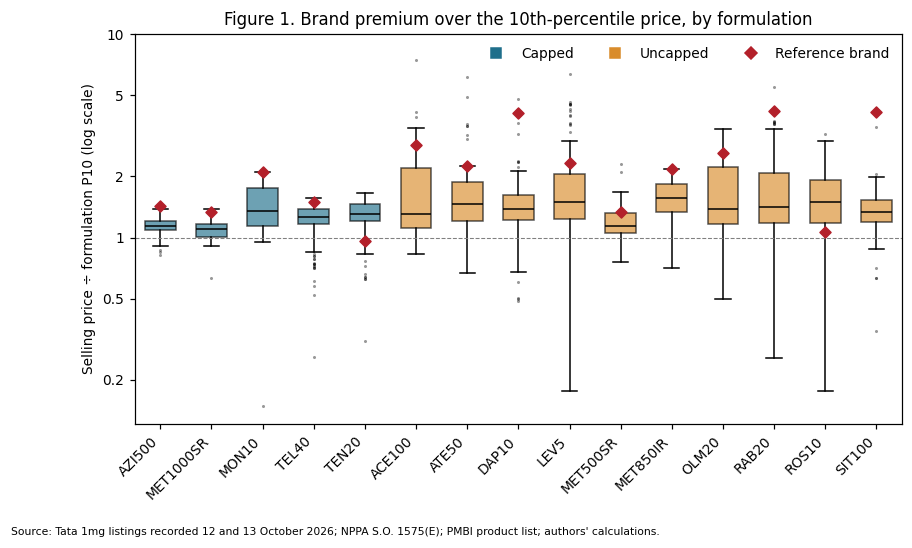

In [26]:
# Figure 1: premium distribution by formulation, with the anchor marked.
fig, ax = plt.subplots(figsize=(9, 4.6))
data = [df.loc[df["formulation_id"] == f, "premium_over_p10"] for f in ORDER]
bp = ax.boxplot(data, patch_artist=True, widths=.6, flierprops=dict(marker=".", markersize=2, alpha=.4), medianprops=dict(color="black"))
for box, f in zip(bp["boxes"], ORDER):
    box.set_facecolor(CAPPED_COLOR if f in capped_ids else UNCAPPED_COLOR); box.set_alpha(.65)
ax.scatter(range(1, 16), [ANCHOR.loc[f, "premium_over_p10"] for f in ORDER], marker="D", s=26, color=ANCHOR_COLOR, zorder=5)
ax.set_yscale("log"); ax.axhline(1, color="grey", lw=.7, ls="--")
ax.set_xticks(range(1, 16)); ax.set_xticklabels(ORDER, rotation=45, ha="right")
ax.set_yticks([.2, .5, 1, 2, 5, 10]); ax.set_yticklabels(["0.2", "0.5", "1", "2", "5", "10"]); ax.minorticks_off()
ax.set_ylabel("Selling price ÷ formulation P10 (log scale)")
ax.set_title("Figure 1. Brand premium over the 10th-percentile price, by formulation")
ax.legend(handles=[Line2D([], [], marker="s", ls="", color=CAPPED_COLOR, label="Capped"), Line2D([], [], marker="s", ls="", color=UNCAPPED_COLOR, label="Uncapped"),
                   Line2D([], [], marker="D", ls="", color=ANCHOR_COLOR, label="Reference brand")], frameon=False, ncol=3, loc="upper right")
fig.text(0, -.11, SOURCE, fontsize=7); fig.savefig(OUT / "figure1_premium_boxplot.png"); plt.show()

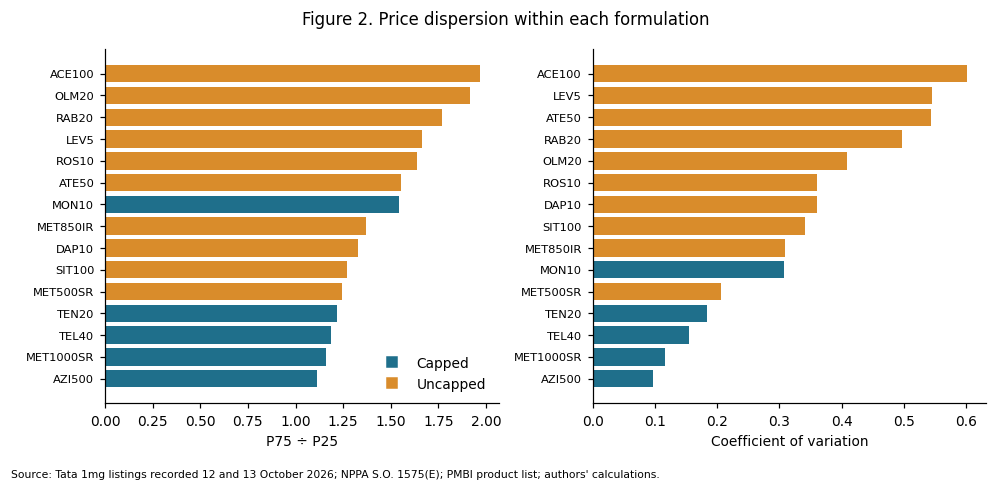

In [27]:
# Figure 2: dispersion by formulation.
fig, axes = plt.subplots(1, 2, figsize=(9, 4.2))
for ax, m, lab in zip(axes, ["p75_p25", "cv"], ["P75 ÷ P25", "Coefficient of variation"]):
    o = disp_main[m].sort_values()
    ax.barh(o.index, o.values, color=[CAPPED_COLOR if f in capped_ids else UNCAPPED_COLOR for f in o.index])
    ax.set_xlabel(lab); ax.spines[["top", "right"]].set_visible(False); ax.tick_params(axis="y", labelsize=7.5)
axes[0].legend(handles=[Line2D([], [], marker="s", ls="", color=CAPPED_COLOR, label="Capped"), Line2D([], [], marker="s", ls="", color=UNCAPPED_COLOR, label="Uncapped")], frameon=False, loc="lower right")
fig.suptitle("Figure 2. Price dispersion within each formulation")
fig.text(0, -.03, SOURCE, fontsize=7); fig.tight_layout(); fig.savefig(OUT / "figure2_dispersion.png"); plt.show()

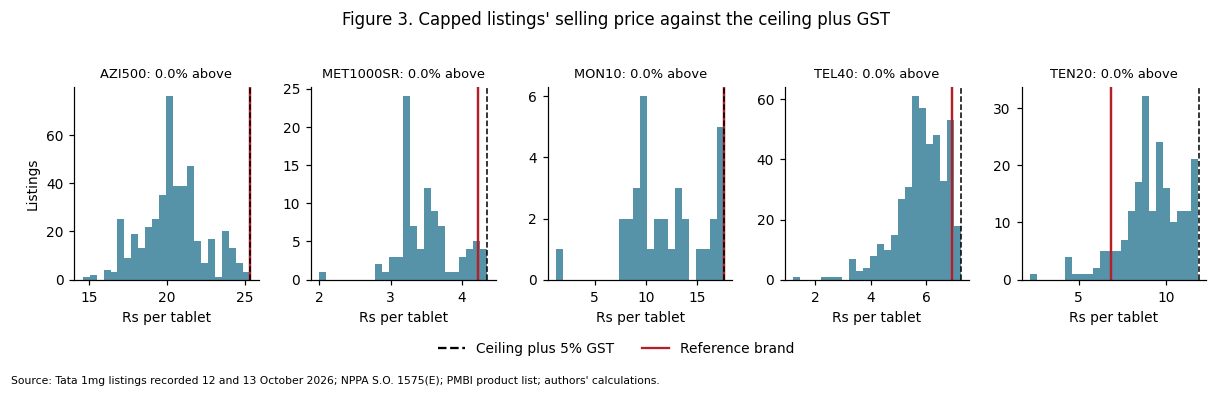

In [28]:
# Figure 3: capped listings against ceiling plus GST.
ids = sorted(capped_ids)
fig, axes = plt.subplots(1, 5, figsize=(11, 2.9))
for ax, f in zip(axes, ids):
    x = cap[cap["formulation_id"] == f]
    ax.hist(x["sp_unit"], bins=24, color=CAPPED_COLOR, alpha=.75)
    ax.axvline(ANCHOR.loc[f, "sp_unit"], color=ANCHOR_COLOR, lw=1.6)
    ax.axvline(x["ceiling_plus_gst"].iloc[0], color="black", ls="--", lw=1, zorder=5)
    ax.set_title(f"{f}: {t4.loc[f, 'share_sp_pct']:.1f}% above", fontsize=8.5)
    ax.set_xlabel("Rs per tablet"); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Listings")
fig.legend(handles=[Line2D([], [], color="black", ls="--", label="Ceiling plus 5% GST"), Line2D([], [], color=ANCHOR_COLOR, label="Reference brand")], frameon=False, ncol=2, loc="lower center", bbox_to_anchor=(.5, -.09))
fig.suptitle("Figure 3. Capped listings' selling price against the ceiling plus GST", y=1.03)
fig.text(0, -.14, SOURCE, fontsize=7); fig.tight_layout(); fig.savefig(OUT / "figure3_ceiling.png"); plt.show()

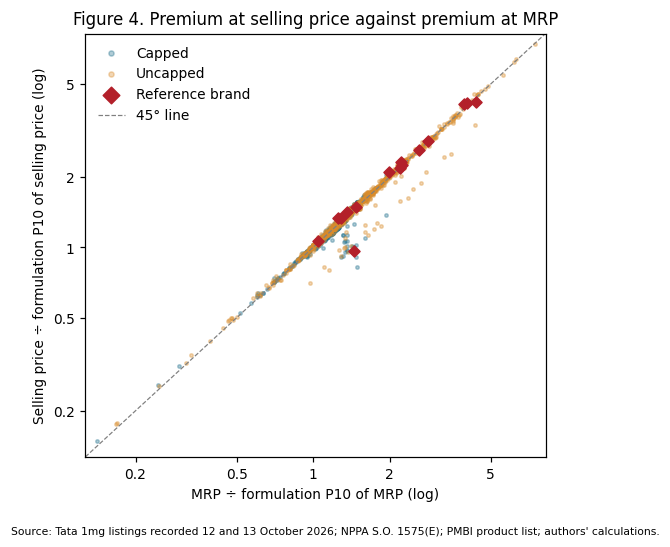

In [29]:
# Figure 4: premium at selling price against premium at MRP.
fig, ax = plt.subplots(figsize=(5.4, 5))
sub_, anc = df[df["is_anchor"] == 0], df[df["is_anchor"] == 1]
for flag_, c, lab in [(1, CAPPED_COLOR, "Capped"), (0, UNCAPPED_COLOR, "Uncapped")]:
    x = sub_[sub_["dpco_capped"] == flag_]
    ax.scatter(x["premium_mrp_p10"], x["premium_over_p10"], s=5, alpha=.35, color=c, label=lab)
ax.scatter(anc["premium_mrp_p10"], anc["premium_over_p10"], marker="D", s=26, color=ANCHOR_COLOR, label="Reference brand", zorder=5)
lim = [min(df["premium_mrp_p10"].min(), df["premium_over_p10"].min()) * .9, max(df["premium_mrp_p10"].max(), df["premium_over_p10"].max()) * 1.1]
ax.plot(lim, lim, color="grey", lw=.8, ls="--", label="45° line")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
for axis in (ax.xaxis, ax.yaxis):
    axis.set_ticks([.2, .5, 1, 2, 5]); axis.set_ticklabels(["0.2", "0.5", "1", "2", "5"]); axis.set_tick_params(which="minor", length=0, labelleft=False, labelbottom=False)
ax.set_xlabel("MRP ÷ formulation P10 of MRP (log)"); ax.set_ylabel("Selling price ÷ formulation P10 of selling price (log)")
ax.set_title("Figure 4. Premium at selling price against premium at MRP"); ax.legend(frameon=False, markerscale=1.5)
fig.text(0, -.03, SOURCE, fontsize=7); fig.savefig(OUT / "figure4_sp_vs_mrp.png"); plt.show()

### Figure 6. Annual cost of chronic medicines

What one tablet a day for a year costs for each of the 11 chronic formulations: the reference brand, the P10 listing on Tata 1mg, the Jan Aushadhi price, and the best seller where it is not the reference brand. Rosuvastatin is shown at its current ₹24.00 pack. The cell reads `table_rupee_therapy_cost.csv`, `table_rupee_anchor_to_best_seller.csv` and `table_rupee_rosuvas_current_pack.csv` (Section 13) and writes `outputs/figure6_annual_cost.png`. It sets its own colours and hides the top and right spines; no figure follows it.

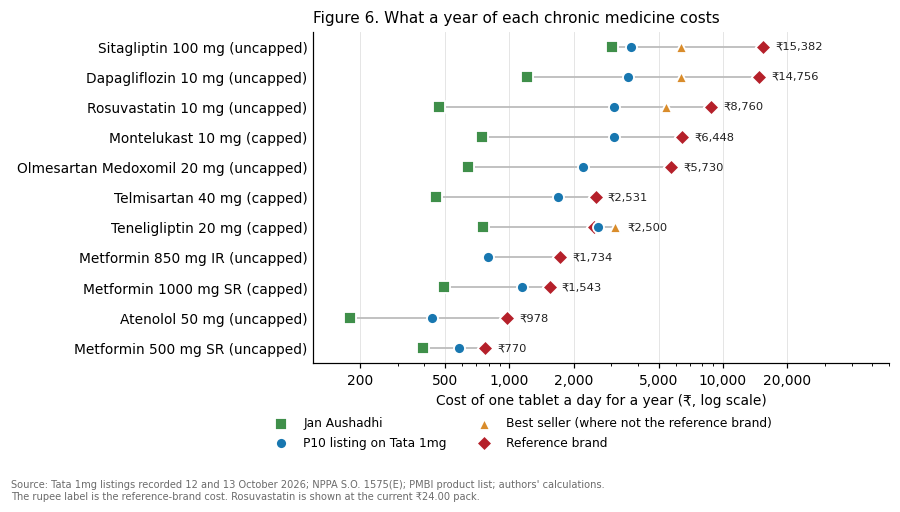

In [30]:
RED, ORANGE, BLUE, GREEN, INK, MUTED = "#B5202A", "#D98C2B", "#1877B0", "#3F8F4A", "#222222", "#6B6B6B"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

cost = pd.read_csv(f"{OUT}/table_rupee_therapy_cost.csv").set_index("formulation_id")
best = pd.read_csv(f"{OUT}/table_rupee_anchor_to_best_seller.csv").set_index("formulation_id")
ros = pd.read_csv(f"{OUT}/table_rupee_rosuvas_current_pack.csv", index_col=0).iloc[:, 0]

d = cost[["formulation", "dpco", "anchor_year_rs", "p10_year_rs", "ja_year_rs"]].copy()
d.loc["ROS10", "anchor_year_rs"] = ros["anchor_year_rs"]          # current 24.00 pack
d["best_year_rs"] = best["best_seller_year_rs"].reindex(d.index)   # only where the best seller is not the reference brand
d = d.sort_values("anchor_year_rs")

fig, ax = plt.subplots(figsize=(8.2, 4.6))
y = np.arange(len(d))
series = [("ja_year_rs", GREEN, "s", "Jan Aushadhi"), ("p10_year_rs", BLUE, "o", "P10 listing on Tata 1mg"),
          ("best_year_rs", ORANGE, "^", "Best seller (where not the reference brand)"),
          ("anchor_year_rs", RED, "D", "Reference brand")]
lo = d[["anchor_year_rs", "p10_year_rs", "ja_year_rs", "best_year_rs"]].min(axis=1)
hi = d[["anchor_year_rs", "p10_year_rs", "ja_year_rs", "best_year_rs"]].max(axis=1)
ax.hlines(y, lo, hi, color="#BDBDBD", lw=1.2, zorder=1)
for col, colour, marker, name in series:
    ax.scatter(d[col], y, s=52, marker=marker, color=colour, edgecolor="white", linewidth=1.2, zorder=4 if col == "p10_year_rs" else 3, label=name)
for yi, (fid, row) in zip(y, d.iterrows()):
    ax.annotate(f"₹{row['anchor_year_rs']:,.0f}", (hi.loc[fid], yi), xytext=(8, 0), textcoords="offset points",
                va="center", fontsize=7.5, color=INK)
ax.set_xscale("log")
ax.set_xlim(120, 60000)
ax.set_xticks([200, 500, 1000, 2000, 5000, 10000, 20000])
ax.set_xticklabels(["200", "500", "1,000", "2,000", "5,000", "10,000", "20,000"])
ax.set_yticks(y)
ax.set_yticklabels([f"{f} ({'capped' if c == 'Capped' else 'uncapped'})" for f, c in zip(d["formulation"], d["dpco"])])
ax.set_xlabel("Cost of one tablet a day for a year (₹, log scale)")
ax.grid(axis="x", color="#E3E3E3", lw=0.6)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.legend(loc="upper center", bbox_to_anchor=(0.36, -0.13), ncol=2, frameon=False, fontsize=8)
ax.set_title("Figure 6. What a year of each chronic medicine costs", fontsize=10, loc="left")
fig.text(0.01, 0.005, SOURCE + "\nThe rupee label is the reference-brand cost. Rosuvastatin is shown at the current ₹24.00 pack.",
         fontsize=6.5, color=MUTED)
fig.tight_layout(rect=(0, 0.05, 1, 1))
fig.savefig(f"{OUT}/figure6_annual_cost.png", dpi=220)
plt.show()

## 16. Export for Notebook 2

`listings_clean.csv` holds the 2,150 usable listings and all derived variables. On Colab, this cell downloads `outputs.zip`; upload `listings_clean.csv` from it when Notebook 2 asks.

In [31]:
df.drop(columns=["key"]).to_csv(OUT / "listings_clean.csv", index=False)
print("Saved", OUT / "listings_clean.csv", df.shape)
print(sorted(p.name for p in OUT.iterdir()))
if IN_COLAB:
    shutil.make_archive("outputs", "zip", OUT)
    from google.colab import files
    files.download("outputs.zip")

Saved outputs\listings_clean.csv (2150, 49)
['appendix_full_regression_output.txt', 'appendix_full_regression_output_corrected.txt', 'check_repeated_rows.csv', 'figure1_premium_boxplot.png', 'figure2_dispersion.png', 'figure3_ceiling.png', 'figure4_sp_vs_mrp.png', 'figure5_robustness.png', 'figure6_annual_cost.png', 'listings_clean.csv', 'table1_formulations.csv', 'table2_anchor_premiums.csv', 'table2b_group_medians.csv', 'table2c_listing_medians.csv', 'table2d_rosuvas_sensitivity.csv', 'table2e_leader_by_bought_recently.csv', 'table2f_leader_tests.csv', 'table3_dispersion.csv', 'table3b_dispersion_tests.csv', 'table3c_upper_lower_dispersion.csv', 'table3d_upper_lower_tests.csv', 'table3e_asymmetry.csv', 'table3f_asymmetry_tests.csv', 'table4_ceiling_compliance.csv', 'table4b_bunching_at_ceiling.csv', 'table4c_listings_above_at_mrp.csv', 'table4d_bunching_at_max.csv', 'table4e_bunching_tests.csv', 'table5_sp_vs_mrp.csv', 'table5b_signed_rank.csv', 'table5c_discounts.csv', 'table6_main_